# SuperStore Orders – Data Cleaning & Exploratory Analysis
**Objective:** Clean the raw SuperStore orders data, remove irrelevant columns, explore key business patterns, and export an analysis-ready CSV for the SQL project.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.options.display.float_format = "{:,.2f}".format

## 2. Load Data

In [2]:
RAW_PATH = "../data/SuperStoreOrders.csv"
df = pd.read_csv(RAW_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 51,290 | Columns: 21


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.00,106.14,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.10,36.04,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.00,29.64,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.50,-26.05,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.10,37.77,4.70,Medium,2011


## 3. Data Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  str    
 1   order_date      51290 non-null  str    
 2   ship_date       51290 non-null  str    
 3   ship_mode       51290 non-null  str    
 4   customer_name   51290 non-null  str    
 5   segment         51290 non-null  str    
 6   state           51290 non-null  str    
 7   country         51290 non-null  str    
 8   market          51290 non-null  str    
 9   region          51290 non-null  str    
 10  product_id      51290 non-null  str    
 11  category        51290 non-null  str    
 12  sub_category    51290 non-null  str    
 13  product_name    51290 non-null  str    
 14  sales           51290 non-null  str    
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null  float64
 1

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Fully duplicated rows:", df.duplicated().sum())
df.nunique().sort_values()

Missing values: 0
Fully duplicated rows: 0


segment               3
category              3
ship_mode             4
order_priority        4
year                  4
market                7
region               13
quantity             14
sub_category         17
discount             27
country             147
customer_name       795
state              1094
order_date         1430
ship_date          1464
sales              2246
product_name       3788
shipping_cost     10037
product_id        10292
profit            24575
order_id          25035
dtype: int64

**Observations**
- No missing values and no fully duplicated rows.
- `sales` is stored as text (thousands separators such as `1,106`), and both date columns are text.
- `region` and `state` are either ambiguous or too granular (see Section 5).

## 4. Data Cleaning

**4.1 Fix data types** – convert `sales` to numeric and dates to `datetime` (day-first format).

In [5]:
df["sales"] = df["sales"].str.replace(",", "", regex=False).astype(float)
df["order_date"] = pd.to_datetime(df["order_date"], format="%d/%m/%Y")
df["ship_date"] = pd.to_datetime(df["ship_date"], format="%d/%m/%Y")
df[["sales", "order_date", "ship_date"]].dtypes

sales                float64
order_date    datetime64[us]
ship_date     datetime64[us]
dtype: object

**4.2 Validate data quality** – text formatting, date logic, and repeated order lines.

In [6]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

print("Ship date earlier than order date:", (df["ship_date"] < df["order_date"]).sum())
print("Negative sales:", (df["sales"] < 0).sum(), "| Zero sales:", (df["sales"] == 0).sum())
print("Repeated (order_id, product_id) pairs:", df.duplicated(["order_id", "product_id"]).sum())

Ship date earlier than order date: 0
Negative sales: 0 | Zero sales: 1
Repeated (order_id, product_id) pairs: 38


- Dates are consistent. One line has `sales = 0` because sales are stored as whole numbers (a very small sale was rounded); it is retained.
- Repeated `(order_id, product_id)` pairs are **kept**: they differ in shipping cost or sales, so they are separate order lines.
- Negative `profit` values are genuine losses, not errors, and are retained.

**4.3 Resolve reused order IDs** – some `order_id` values are shared by different customers or dates, so they do not identify a single order.

In [7]:
keys = ["order_id", "customer_name", "order_date"]
print("Order IDs before fix:", df["order_id"].nunique(), "| True distinct orders:", df.groupby(keys).ngroups)

lookup = df[keys].drop_duplicates().sort_values(["order_id", "order_date", "customer_name"])
lookup["seq"] = lookup.groupby("order_id").cumcount() + 1
df = df.merge(lookup, on=keys, how="left")
df["order_id"] = np.where(df["seq"] > 1, df["order_id"] + "-" + df["seq"].astype(str), df["order_id"])
df = df.drop(columns="seq")

print("Order IDs after fix: ", df["order_id"].nunique())

Order IDs before fix: 25035 | True distinct orders: 25754
Order IDs after fix:  25754


A suffix (`-2`, `-3`) is added to reused IDs so that every `order_id` now represents exactly one order. This keeps order counts and average order value accurate in SQL.

## 5. Remove Irrelevant Columns

| Column | Reason for removal |
|---|---|
| `year` | Redundant – can be derived from `order_date` |
| `state` | Too granular (1,094 values) and inconsistent across countries |
| `region` | Overlaps with `market` and is ambiguous (e.g., *Central* appears in three markets) |
| `product_id` | `product_name` already identifies the product; IDs add no analytical value |

In [8]:
df = df.drop(columns=["year", "state", "region", "product_id"])
df.insert(0, "order_line_id", np.arange(1, len(df) + 1))   # unique row key for SQL
df[["profit", "shipping_cost"]] = df[["profit", "shipping_cost"]].round(2)
print(f"Remaining columns ({df.shape[1]}):", list(df.columns))

Remaining columns (18): ['order_line_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name', 'segment', 'country', 'market', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority']


## 6. Cleaned Data Summary

In [9]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
order_line_id,"51,290.00","25,645.50",1.00,"12,823.25","25,645.50","38,467.75","51,290.00","14,806.29"
order_date,51290,2013-05-11 21:26:49.155780,2011-01-01 00:00:00,2012-06-19 00:00:00,2013-07-08 00:00:00,2014-05-22 00:00:00,2014-12-31 00:00:00,NaN
ship_date,51290,2013-05-15 20:42:42.745174,2011-01-03 00:00:00,2012-06-23 00:00:00,2013-07-12 00:00:00,2014-05-26 00:00:00,2015-01-07 00:00:00,NaN
sales,"51,290.00",246.50,0.00,31.00,85.00,251.00,"22,638.00",487.57
quantity,"51,290.00",3.48,1.00,2.00,3.00,5.00,14.00,2.28
discount,"51,290.00",0.14,0.00,0.00,0.00,0.20,0.85,0.21
profit,"51,290.00",28.64,"-6,599.98",0.00,9.24,36.81,"8,399.98",174.42
shipping_cost,"51,290.00",26.38,0.00,2.61,7.79,24.45,933.57,57.30


In [10]:
df.describe(include=['object', 'string']).T[['count', 'unique', 'top']]

,count,unique,top
order_id,51290,25754,CA-2014-100111
ship_mode,51290,4,Standard Class
customer_name,51290,795,Muhammed Yedwab
segment,51290,3,Consumer
country,51290,147,United States
market,51290,7,APAC
category,51290,3,Office Supplies
sub_category,51290,17,Binders
product_name,51290,3788,Staples
order_priority,51290,4,Medium


## 7. Exploratory Data Analysis

**7.1 Key Performance Indicators**

In [11]:
kpi = pd.Series({
    "Total Orders": df["order_id"].nunique(),
    "Unique Customers": df["customer_name"].nunique(),
    "Countries": df["country"].nunique(),
    "Total Sales": df["sales"].sum(),
    "Total Profit": df["profit"].sum(),
    "Profit Margin (%)": df["profit"].sum() / df["sales"].sum() * 100,
    "Avg Discount (%)": df["discount"].mean() * 100,
    "Loss-Making Lines (%)": (df["profit"] < 0).mean() * 100,
})
kpi.to_frame("Value")

,Value
Total Orders,"25,754.00"
Unique Customers,795.00
Countries,147.00
Total Sales,"12,642,905.00"
Total Profit,"1,469,034.05"
Profit Margin (%),11.62
Avg Discount (%),14.29
Loss-Making Lines (%),24.45


**7.2 Yearly Performance**

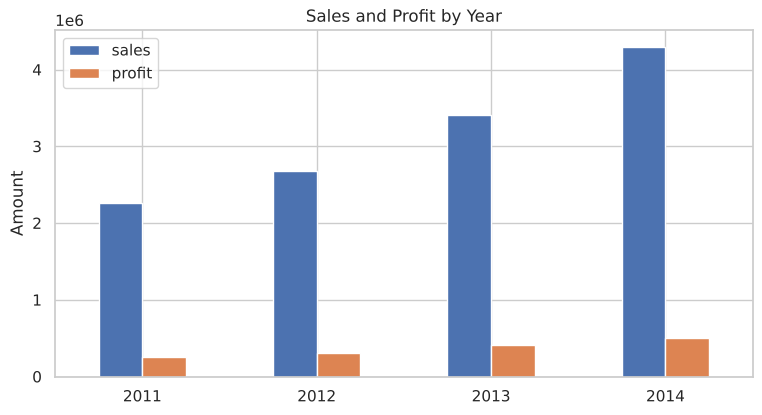

,sales,profit,sales_growth_%
order_year,,,
2011,"2,259,511.00","248,940.51",NaN
2012,"2,677,493.00","307,415.30",18.50
2013,"3,405,860.00","408,512.23",27.20
2014,"4,300,041.00","504,166.01",26.25


In [12]:
df["order_year"] = df["order_date"].dt.year
yearly = df.groupby("order_year").agg(sales=("sales", "sum"), profit=("profit", "sum"))
yearly["sales_growth_%"] = yearly["sales"].pct_change() * 100

ax = yearly[["sales", "profit"]].plot(kind="bar", rot=0)
ax.set_title("Sales and Profit by Year"); ax.set_xlabel(""); ax.set_ylabel("Amount")
plt.show()
yearly

Sales have grown every year, from about 2.26M in 2011 to 4.30M in 2014, with profit rising in line.

**7.3 Monthly Seasonality**

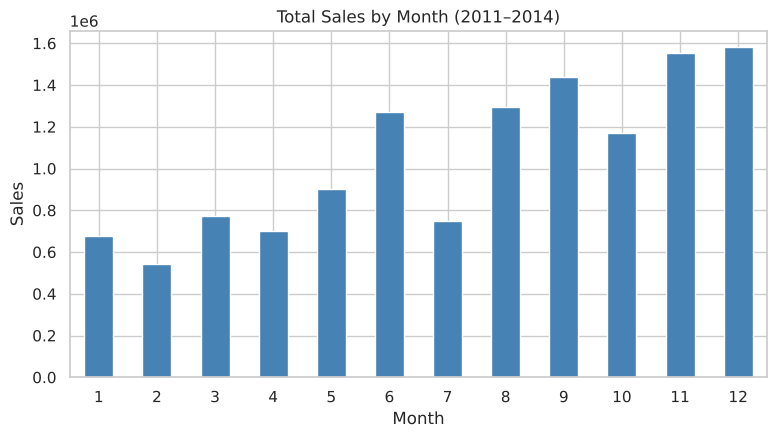

In [13]:
monthly = df.groupby(df["order_date"].dt.month)["sales"].sum()
ax = monthly.plot(kind="bar", rot=0, color="steelblue")
ax.set_title("Total Sales by Month (2011–2014)"); ax.set_xlabel("Month"); ax.set_ylabel("Sales")
plt.show()

Sales are highest in November and December, with September also strong; February is the weakest month.

**7.4 Category and Sub-Category Profitability**

,sales,profit,margin_%
category,,,
Furniture,"4,110,884.00","286,781.94",6.98
Office Supplies,"3,787,330.00","518,472.86",13.69
Technology,"4,744,691.00","663,779.25",13.99


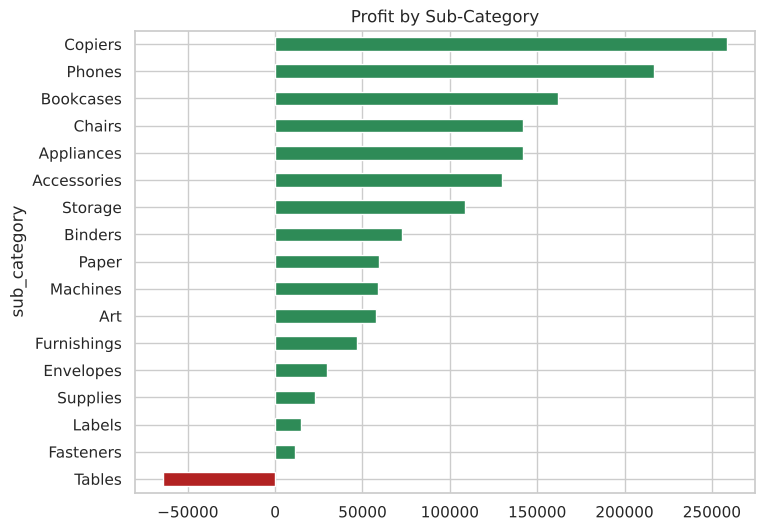

In [14]:
cat = df.groupby("category").agg(sales=("sales", "sum"), profit=("profit", "sum"))
cat["margin_%"] = cat["profit"] / cat["sales"] * 100
display(cat)

sub = df.groupby("sub_category")["profit"].sum().sort_values()
colors = ["firebrick" if v < 0 else "seagreen" for v in sub]
sub.plot(kind="barh", color=colors, figsize=(8, 6), title="Profit by Sub-Category")
plt.show()

Technology generates the most profit. **Tables** is the only loss-making sub-category (about –64K).

**7.5 Market and Country Performance**

,sales,profit,margin_%
market,,,
APAC,"3,585,833.00","437,577.44",12.20
EU,"2,938,139.00","372,829.57",12.69
US,"2,297,354.00","286,396.54",12.47
LATAM,"2,164,687.00","221,643.63",10.24
EMEA,"806,184.00","43,897.99",5.45
Africa,"783,776.00","88,871.49",11.34
Canada,"66,932.00","17,817.39",26.62


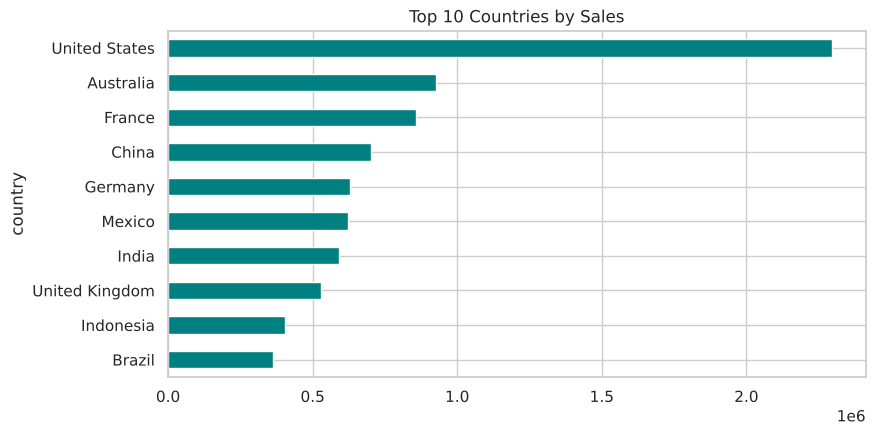

In [15]:
market = df.groupby("market").agg(sales=("sales", "sum"), profit=("profit", "sum"))
market["margin_%"] = market["profit"] / market["sales"] * 100
display(market.sort_values("sales", ascending=False))

top_countries = df.groupby("country")["sales"].sum().nlargest(10).sort_values()
top_countries.plot(kind="barh", title="Top 10 Countries by Sales", color="teal")
plt.show()

APAC leads in sales. EMEA has the weakest margin (5.4%). Canada is small but the most profitable by margin (26.6%).

**7.6 Customer Segments**

In [16]:
seg = df.groupby("segment").agg(orders=("order_id", "nunique"), sales=("sales", "sum"), profit=("profit", "sum"))
seg["margin_%"] = seg["profit"] / seg["sales"] * 100
seg

,orders,sales,profit,margin_%
segment,,,,
Consumer,13305,"6,508,141.00","749,239.24",11.51
Corporate,7732,"3,824,808.00","442,785.63",11.58
Home Office,4717,"2,309,956.00","277,009.18",11.99


**7.7 Impact of Discounts on Profit**

,order_lines,total_profit,avg_profit
discount,,,
No discount,29009,"1,770,694.68",61.04
Up to 20%,10953,"513,021.83",46.84
21–40%,4367,"-187,271.10",-42.88
Above 40%,6961,"-627,411.36",-90.13


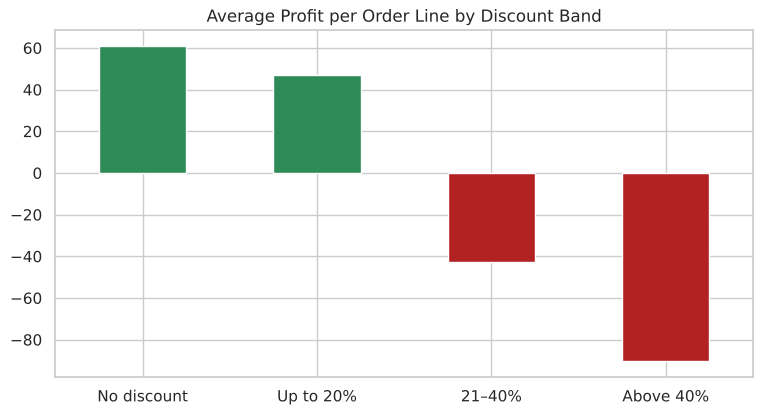

In [17]:
bands = pd.cut(df["discount"], [-0.01, 0, 0.2, 0.4, 1],
               labels=["No discount", "Up to 20%", "21–40%", "Above 40%"])
disc = df.groupby(bands, observed=True)["profit"].agg(["count", "sum", "mean"])
disc.columns = ["order_lines", "total_profit", "avg_profit"]
display(disc)

disc["avg_profit"].plot(kind="bar", rot=0, color=["seagreen", "seagreen", "firebrick", "firebrick"],
                        title="Average Profit per Order Line by Discount Band")
plt.xlabel(""); plt.show()

Order lines with discounts above 20% lose money on average (about –43 per line at 21–40% and –90 above 40%) – the most actionable finding in the dataset.

**7.8 Shipping Performance**

,orders,avg_days,avg_cost
ship_mode,,,
Same Day,1349,0.04,42.94
First Class,3847,2.18,41.05
Second Class,5146,3.23,30.47
Standard Class,15412,5.00,19.97


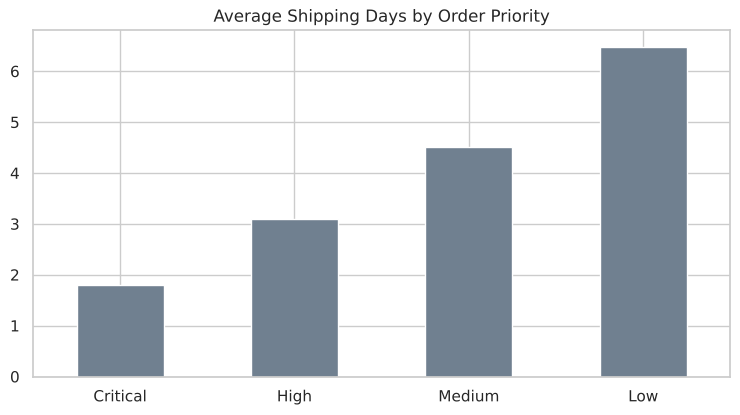

In [18]:
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days
ship = df.groupby("ship_mode").agg(orders=("order_id", "nunique"),
                                   avg_days=("shipping_days", "mean"),
                                   avg_cost=("shipping_cost", "mean"))
display(ship.sort_values("avg_days"))

df.groupby("order_priority")["shipping_days"].mean().reindex(["Critical", "High", "Medium", "Low"]) \
  .plot(kind="bar", rot=0, color="slategray", title="Average Shipping Days by Order Priority")
plt.xlabel(""); plt.show()

Faster ship modes cost about twice as much as Standard Class, and priority levels are reflected correctly in delivery time.

**7.9 Top Customers**

In [19]:
(df.groupby("customer_name").agg(sales=("sales", "sum"), profit=("profit", "sum"))
   .nlargest(5, "sales"))

,sales,profit
customer_name,,
Tom Ashbrook,"40,489.00","6,312.01"
Tamara Chand,"37,453.00","8,672.89"
Greg Tran,"35,552.00","5,214.12"
Christopher Conant,"35,187.00","5,603.34"
Sean Miller,"35,170.00",-409.71


## 8. Key Insights

1. **Strong growth:** Sales grew 90% between 2011 and 2014 (≈2.26M → 4.30M), with a stable profit margin of about 11–12%.
2. **Technology leads:** It earns the highest profit, while **Tables** is the only loss-making sub-category.
3. **Discounts hurt:** Order lines discounted above 20% lose money on average.
4. **Market gaps:** APAC is the largest market; EMEA has the lowest margin (5.4%).
5. **Seasonality:** Sales are highest in November and December; February is the weakest month.
6. **Segments:** Consumer is the largest segment (about 51% of sales), but margins are similar across all three.

## 9. Export Cleaned Data

In [20]:
export_cols = ["order_line_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_name",
               "segment", "country", "market", "category", "sub_category", "product_name",
               "sales", "quantity", "discount", "profit", "shipping_cost", "order_priority"]
clean = df[export_cols].copy()
clean.to_csv("../data/superstore_cleaned.csv", index=False, date_format="%Y-%m-%d")
print(f"Exported {clean.shape[0]:,} rows and {clean.shape[1]} columns.")

Exported 51,290 rows and 18 columns.
